In [2]:
import pandas as pd

df = pd.read_csv('ae_monthly_merged_apr2023_sep2026.csv')
df['month'] = pd.to_datetime(df['month'])
print(df.shape)
print(df['month'].nunique())

(8329, 23)
42


In [3]:
att_cols = [c for c in df.columns if c.startswith('A&E attendances')]
over_cols = [c for c in df.columns if c.startswith('Attendances over 4hrs')]

df['attendances'] = df[att_cols].sum(axis=1)
df['over_4hrs'] = df[over_cols].sum(axis=1)

type1_codes = df.loc[df['A&E attendances Type 1'] > 0, 'Org Code'].unique()
trusts = df[df['Org Code'].isin(type1_codes)].copy()

months_per_trust = trusts.groupby('Org Code')['month'].nunique()
trusts = trusts[trusts['Org Code'].isin(months_per_trust[months_per_trust == 42].index)].copy()

trusts['perf'] = (1 - trusts['over_4hrs'] / trusts['attendances']) * 100

zero_breach = trusts[trusts['over_4hrs'] == 0]
print(trusts['Org Code'].nunique(), trusts.shape)
print(len(zero_breach))
print(zero_breach.groupby('month').size())

120 (5040, 26)
28
month
2023-04-01    14
2023-05-01    14
dtype: int64


In [4]:
trusts = trusts[trusts['month'] >= '2023-06-01'].copy()

print(trusts.shape)
print(trusts['month'].nunique(), trusts['month'].min(), trusts['month'].max())
print((trusts['over_4hrs'] == 0).sum())
print(trusts['perf'].describe().round(1))

(4800, 26)
40 2023-06-01 00:00:00 2026-09-01 00:00:00
0
count    4800.0
mean       70.9
std         8.0
min        41.3
25%        65.9
50%        71.4
75%        76.2
max        98.1
Name: perf, dtype: float64


In [5]:
clean = trusts[['Org Code', 'Org name', 'month', 'attendances', 'over_4hrs', 'perf']]
clean.to_csv('trusts_perf_clean.csv', index=False)

from google.colab import files
files.download('trusts_perf_clean.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

69.06 1.62 73.35 64.76


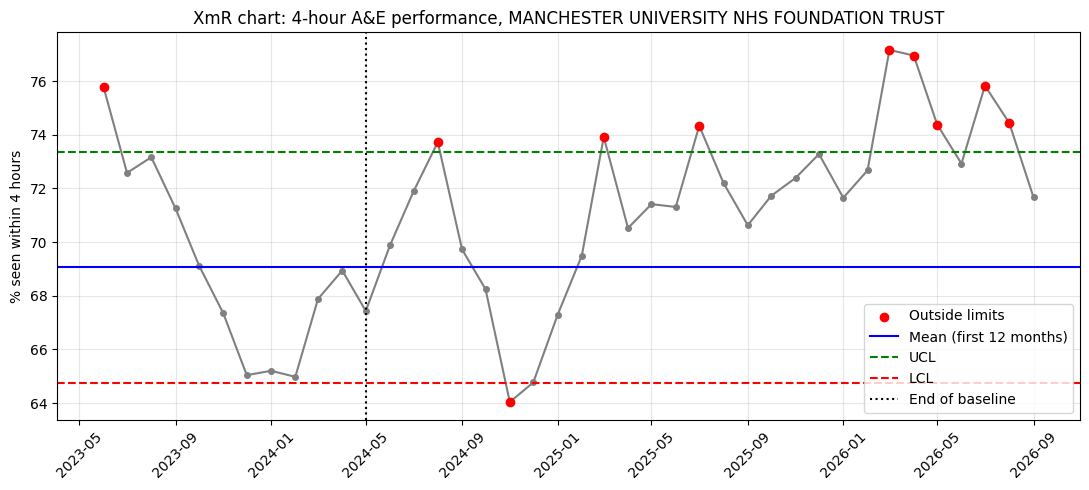

10


In [6]:
import numpy as np
import matplotlib.pyplot as plt

trust = trusts[trusts['Org Code'] == 'R0A'].sort_values('month').reset_index(drop=True)
x = trust['perf'].values
baseline = x[:12]

mean = baseline.mean()
mr_bar = np.abs(np.diff(baseline)).mean()
ucl = mean + 2.66 * mr_bar
lcl = mean - 2.66 * mr_bar

print(round(mean, 2), round(mr_bar, 2), round(ucl, 2), round(lcl, 2))

outside = (trust['perf'] > ucl) | (trust['perf'] < lcl)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(trust['month'], trust['perf'], color='gray', marker='o', markersize=4)
ax.scatter(trust.loc[outside, 'month'], trust.loc[outside, 'perf'], color='red', zorder=3, label='Outside limits')
ax.axhline(mean, color='blue', label='Mean (first 12 months)')
ax.axhline(ucl, color='green', linestyle='--', label='UCL')
ax.axhline(lcl, color='red', linestyle='--', label='LCL')
ax.axvline(trust['month'].iloc[11], color='black', linestyle=':', label='End of baseline')
ax.set_title('XmR chart: 4-hour A&E performance, ' + trust['Org name'].iloc[0])
ax.set_ylabel('% seen within 4 hours')
ax.legend()
ax.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(outside.sum())

In [8]:
import numpy as np

def run_flags(cond, min_len):
    cond = np.asarray(cond, dtype=bool)
    out = np.zeros(len(cond), dtype=bool)
    start = None
    for i in range(len(cond) + 1):
        on = i < len(cond) and cond[i]
        if on and start is None:
            start = i
        if not on and start is not None:
            if i - start >= min_len:
                out[start:i] = True
            start = None
    return out

def xmr_signals(x, n_base=12, run_len=7, mask_baseline=True):
    x = np.asarray(x, dtype=float)
    base = x[:n_base]
    mean = base.mean()
    mr_bar = np.abs(np.diff(base)).mean()
    ucl = mean + 2.66 * mr_bar
    lcl = mean - 2.66 * mr_bar
    sigma = mr_bar / 1.128
    upper2 = mean + 2 * sigma
    lower2 = mean - 2 * sigma
    n = len(x)

    high = np.zeros(n, dtype=bool)
    low = np.zeros(n, dtype=bool)

    high |= x > ucl
    low |= x < lcl

    high |= run_flags(x > mean, run_len)
    low |= run_flags(x < mean, run_len)

    steps = np.diff(x)
    up = run_flags(steps > 0, run_len - 1)
    down = run_flags(steps < 0, run_len - 1)
    up_pts = np.zeros(n, dtype=bool)
    down_pts = np.zeros(n, dtype=bool)
    up_pts[:-1] |= up
    up_pts[1:] |= up
    down_pts[:-1] |= down
    down_pts[1:] |= down
    high |= up_pts
    low |= down_pts

    for i in range(2, n):
        w = slice(i - 2, i + 1)
        if (x[w] > upper2).sum() >= 2:
            high[w] |= x[w] > upper2
        if (x[w] < lower2).sum() >= 2:
            low[w] |= x[w] < lower2

    if mask_baseline:
        high[:n_base] = False
        low[:n_base] = False

    return mean, ucl, lcl, high, low

In [9]:
trust = trusts[trusts['Org Code'] == 'R0A'].sort_values('month').reset_index(drop=True)
mean, ucl, lcl, high, low = xmr_signals(trust['perf'].values)

print(high.sum(), low.sum(), (high | low).sum())
print(trust.loc[low, 'month'].dt.strftime('%b %Y').tolist())

21 2 23
['Nov 2024', 'Dec 2024']


In [10]:
parts = []
for code, g in trusts.sort_values('month').groupby('Org Code'):
    g = g.reset_index(drop=True)
    mean, ucl, lcl, high, low = xmr_signals(g['perf'].values)
    out = g[['Org Code', 'Org name', 'month', 'perf']].copy()
    out['mean'] = mean
    out['ucl'] = ucl
    out['lcl'] = lcl
    out['high_signal'] = high
    out['low_signal'] = low
    parts.append(out)

flags = pd.concat(parts, ignore_index=True)
print(flags.shape)

(4800, 9)


In [11]:
months = sorted(flags['month'].unique())
last3 = months[-3:]
recent = flags[flags['month'].isin(last3)]

summary = flags.groupby(['Org Code', 'Org name']).agg(
    worse_points=('low_signal', 'sum'),
    better_points=('high_signal', 'sum')
).reset_index()

r3 = recent.groupby('Org Code').agg(
    worse_recent=('low_signal', 'any'),
    better_recent=('high_signal', 'any')
).reset_index()
summary = summary.merge(r3, on='Org Code')

def status(row):
    if row['worse_recent']:
        return 'Deteriorating'
    if row['better_recent']:
        return 'Improving'
    return 'Normal variation'

summary['status'] = summary.apply(status, axis=1)
print(summary['status'].value_counts())
summary[summary['status'] == 'Deteriorating'].sort_values('worse_points', ascending=False)[['Org Code', 'Org name', 'worse_points']].head(10)

status
Improving           85
Normal variation    26
Deteriorating       18
Name: count, dtype: int64


,Org Code,Org name,worse_points
98,RTP,SURREY AND SUSSEX HEALTHCARE NHS TRUST,25
101,RVR,EPSOM AND ST HELIER UNIVERSITY HOSPITALS NHS T...,25
79,RNZ,SALISBURY NHS FOUNDATION TRUST,24
121,RXL,BLACKPOOL TEACHING HOSPITALS NHS FOUNDATION TRUST,23
108,RWF,MAIDSTONE AND TUNBRIDGE WELLS NHS TRUST,23
44,RH5,SOMERSET NHS FOUNDATION TRUST,23
72,RN3,GREAT WESTERN HOSPITALS NHS FOUNDATION TRUST,21
103,RVW,NORTH TEES AND HARTLEPOOL NHS FOUNDATION TRUST,20
58,RJN,EAST CHESHIRE NHS TRUST,19
25,RCB,YORK AND SCARBOROUGH TEACHING HOSPITALS NHS FO...,18


In [12]:
flags.to_csv('spc_flags_all_trusts.csv', index=False)
summary.to_csv('spc_trust_summary.csv', index=False)

from google.colab import files
files.download('spc_flags_all_trusts.csv')
files.download('spc_trust_summary.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
flags = flags.sort_values(['Org Code', 'month'])
months = sorted(flags['month'].unique())
last3 = months[-3:]
recent = flags[flags['month'].isin(last3)]

summary = flags.groupby('Org Code').agg(
    org_name=('Org name', 'last'),
    worse_points=('low_signal', 'sum'),
    better_points=('high_signal', 'sum')
).reset_index()

r3 = recent.groupby('Org Code').agg(
    worse_recent=('low_signal', 'any'),
    better_recent=('high_signal', 'any')
).reset_index()
summary = summary.merge(r3, on='Org Code')

def status(row):
    if row['worse_recent']:
        return 'Deteriorating'
    if row['better_recent']:
        return 'Improving'
    return 'Normal variation'

summary['status'] = summary.apply(status, axis=1)
print(len(summary))
print(summary['status'].value_counts())
summary[summary['status'] == 'Deteriorating'].sort_values('worse_points', ascending=False)[['Org Code', 'org_name', 'worse_points']].head(10)

120
status
Improving           77
Normal variation    25
Deteriorating       18
Name: count, dtype: int64


,Org Code,org_name,worse_points
92,RTP,SURREY AND SUSSEX HEALTHCARE NHS TRUST,25
95,RVR,EPSOM AND ST HELIER UNIVERSITY HOSPITALS NHS T...,25
74,RNZ,SALISBURY NHS FOUNDATION TRUST,24
112,RXL,BLACKPOOL TEACHING HOSPITALS NHS FOUNDATION TRUST,23
101,RWF,MAIDSTONE AND TUNBRIDGE WELLS NHS TRUST,23
40,RH5,SOMERSET NHS FOUNDATION TRUST,23
67,RN3,GREAT WESTERN HOSPITALS NHS FOUNDATION TRUST,21
97,RVW,NORTH TEES AND HARTLEPOOL NHS FOUNDATION TRUST,20
53,RJN,EAST CHESHIRE NHS TRUST,19
21,RCB,YORK AND SCARBOROUGH TEACHING HOSPITALS NHS FO...,18


In [14]:
summary.to_csv('spc_trust_summary.csv', index=False)

from google.colab import files
files.download('spc_trust_summary.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>